### Scrape Reviews from *ProductHunt*

In [ ]:
import requests
import re
import random
from time import sleep
from bs4 import BeautifulSoup
import pandas as pd
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import matplotlib.pyplot as plt

g2_url = "https://www.producthunt.com/products/outpost-club/reviews?feed=single&filter=all&page="

def paginate():
    r = requests.get(g2_url + str(1))
    soup = BeautifulSoup(r.text, 'html.parser')
    
    pagination = soup.find_all("a")
    pages = []

    for link in pagination:
        href = link.get("href", "")

        if "/products/outpost-club/reviews?feed=single&filter=all&page" in href:
            page_num = href.rsplit("=", 1)[-1]
            pages.append(page_num)

    return pages


In [ ]:
def scrape(page_nxt):
    reviews_arr = []

    for page in range(1, int(page_nxt) + 1):
        r = requests.get(g2_url + str(page))

        soup = BeautifulSoup(r.text, 'html.parser')

        reviews = soup.find_all("div", class_="prose")

        for review in reviews:
            if len(review.contents) != 0:
                reviews_arr.append(review.contents[0])

        delay = random.uniform(1,5)
        sleep(delay)

    return reviews_arr   


pages = paginate()

for page in pages[:-1]:
    scraped_reviews = scrape(page)

    df = pd.DataFrame({"Review": scraped_reviews})

    df.to_excel("reviews.xlsx")



### *Sentiment Analysis*

In [ ]:
review_xlsx = pd.read_excel("reviews.xlsx")
review_col = review_xlsx["Review"].to_list()

for sentence in review_col:
    sid = SentimentIntensityAnalyzer()
    
    print(sentence)
    ss = sid.polarity_scores(sentence)

    for k in sorted(ss):
        print('{0}: {1}, '.format(k, ss[k]), end='')
        print()

### *Word Frequency Analysis*

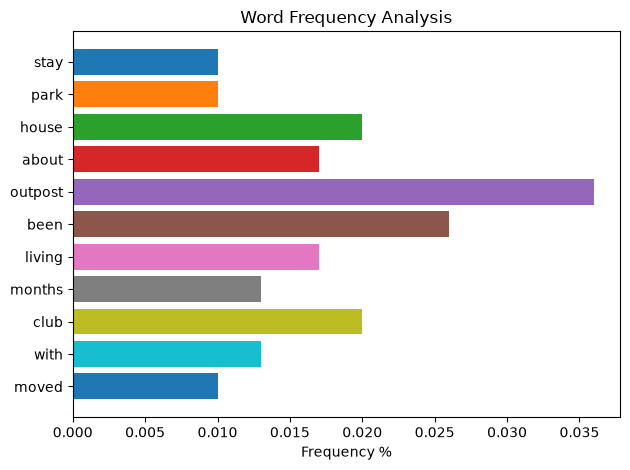

In [180]:
fig, ax = plt.subplots()

review_str = review_xlsx["Review"].to_string()

# Filter for only alphabets
words = re.findall(r"\b[a-zA-Z']+\b", review_str.lower())


word_count = {}
word_len = len(words)

for word in words:
    # Get words greater than 3 to filter common and filler words
    if len(word) > 3:
        if word in word_count:
            word_count[word] += 1
        else:
            word_count[word] = 1
    else:
        pass


# Word Frequency Calculation
word_freq = {}

for word in word_count:
    word_freq[word] = round(word_count[word] / word_len, 3)

    #print(f"{word} - {word_freq[word]}")

    if word_freq[word] >= 0.01:
        ax.barh(word, word_freq[word], align="center")
    #word
    #word_freq[word]


ax.yaxis.set_inverted(True)
ax.set_xlabel('Frequency %')
ax.set_title('Word Frequency Analysis')
plt.tight_layout()
plt.show()